In [2]:
import numpy as np
import matplotlib.pyplot as plt
import meshio

Warning: Unknown index 4. Skipping.

Warning: Zone specification not supported yet (interior, interior-surface_body). Skipping.

Warning: Zone specification not supported yet (fluid, surface_body). Skipping.

Warning: Zone specification not supported yet (pressure-outlet, outlet). Skipping.

Warning: Zone specification not supported yet (wall, wall1). Skipping.

Warning: Zone specification not supported yet (wall, wall2). Skipping.

Warning: Zone specification not supported yet (wall, wall3). Skipping.

Warning: Zone specification not supported yet (velocity-inlet, inlet). Skipping.

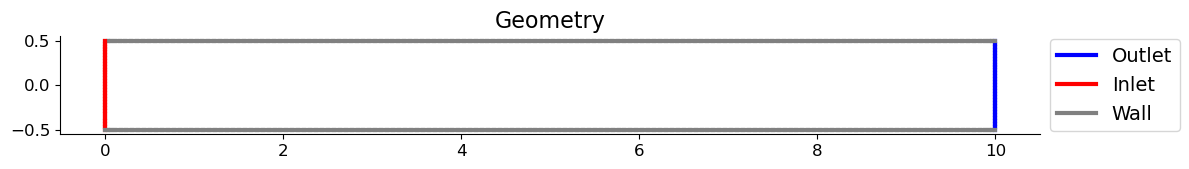

In [3]:
mesh = meshio.read(r"Input/mesh.msh")
points = mesh.points[:, :2]

plt.figure(figsize=(12, 2))

colors = plt.cm.tab10(np.linspace(0, 1, len(mesh.cells)))


labels_used = set()

for i, cell_block in enumerate(mesh.cells):
    if i == 0:
        continue
    
    if cell_block.type == "line":
        lines = cell_block.data
        label_text = None

        if i in [3, 4]:
            color = "gray"
            if "Wall" not in labels_used:
                label_text = "Wall"
                labels_used.add("Wall")

        elif i == 1:
            color = "blue"
            if "Outlet" not in labels_used:
                label_text = "Outlet"
                labels_used.add("Outlet")

        elif i in [2, 5]:
            color = "red"
            if "Inlet" not in labels_used:
                label_text = "Inlet"
                labels_used.add("Inlet")

        else:
            color = colors[i]
            label_text = f"Line block {i}"

        for j, line in enumerate(lines):
            p1 = points[line[0]]
            p2 = points[line[1]]

            plt.plot(
                [p1[0], p2[0]],
                [p1[1], p2[1]],
                color=color,
                linewidth=3,
                label=label_text if j == 0 and label_text is not None else None
            )

ax = plt.gca()
ax.set_aspect("equal")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=14
)

plt.title("Geometry", fontsize=16)
plt.tick_params(axis="both", which="major", labelsize=12)
plt.tight_layout()

plt.savefig("Input/mesh_geometry.png", dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()
